<a href="https://colab.research.google.com/github/yanapatt/MarisaNeXt/blob/main/data/Preparing_MushroomA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Preparing Dataset**
---
Dataset: Mushroom Common Genus's (MushroomA)  
มีจำนวนทั้งหมด 9 Classes

Step

1.   Upload zip file dataset จาก Google Drive มาไว้บน Runtime Directory
2.   `Rename folder ใน runtime directory จาก _RAW ให้เป็น _CLEAN`
3.   ทำ Section 2 ให้ถึง Export bad images ก่อน แล้วไป Recheck image ใน Google Drive
4.   List รายชื่อไฟล์ที่จะลบแบบ csv ไฟล์ ตั้งชื่อไฟล์ให้ลงท้ายด้วย _TO_DELETE
5.   เริ่มกระบวนการ 1 ใหม่ หลังจากมี _TO_DELETE แล้ว (ให้ Visualization Image ก่อนลบภาพไม่งั้นจะ Error ถ้าอยากจะแสดงภาพที่ลบออกไปแล้ว และเสียเวลา Load ไฟล์มาใหม่)



In [ ]:
%%capture
!pip install imagededup

In [ ]:
import os
import shutil
import zipfile
import json
import pickle

import numpy as np
import pandas as pd
import random as rd
from sklearn.model_selection import train_test_split

## **Section 1: Setting directory**

### **Drive directory**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
drive_dir = '/content/drive/MyDrive/projectMushroom'
data_name = 'MushroomA'
drive_data_dir = f'{drive_dir}/data/{data_name}'
bad_data_dir = f'{drive_data_dir}/imagesQuarantine'
font_dir = f'{drive_dir}/assets/fonts'

os.makedirs(bad_data_dir, exist_ok=True)
os.chdir(drive_dir)
print(f'Current directory: {os.getcwd()}')

Current directory: /content/drive/MyDrive/projectMushroom


In [ ]:
import src.reproducibility as reproducibility
import src.buildDirectory as buildDirectory
import src.preprocessing as preprocessing
import src.visualization as visualization

visualization.matplotlib_font(font_dir=font_dir, prefer_name='Times-Roman')

'OPTITimes-Roman'

### **Runtime directory**

In [ ]:
SEED = 42
reproducibility.global_seed(seed=SEED)

Global Seed set to: 42


In [ ]:
runtime_dir = '/content'
runtime_data_dir = f'{runtime_dir}/data'
runtime_datasplit_dir = f'{runtime_data_dir}/{data_name}_SPLIT'
runtime_dataclean_dir = f'{runtime_data_dir}/{data_name}_CLEAN'

os.makedirs(runtime_data_dir, exist_ok=True)
os.makedirs(runtime_datasplit_dir, exist_ok=True)
os.makedirs(runtime_dataclean_dir, exist_ok=True)

In [ ]:
with zipfile.ZipFile(f'{drive_data_dir}/{data_name}_RAW.zip', 'r') as zip_ref:
    zip_ref.extractall(runtime_data_dir)
print(f'Dataset has been extracted to {runtime_data_dir}')

Dataset has been extracted to /content/data


## **Section 2: Verify images**

### **Check basic images component**

In [ ]:
verify_report = preprocessing.verify_images(
    data_dir=runtime_data_dir,
    check_solid=True
)

[Log]: Extensions detect .jpg
[Log]: Total images found: 6714


Verifying images: 100%|██████████| 6714/6714 [00:45<00:00, 147.08it/s]


--- Summary ---
Total issues found: 3


In [ ]:
verify_report_df = pd.DataFrame(verify_report)
verify_report_df.to_csv(f'{bad_data_dir}/{data_name}_VERIFY.csv', index=False)

In [ ]:
verify_report_df

,filepaths,filename,label,issue
0,/content/data/MushroomA_RAW/Russula/092_43B354...,092_43B354vYxm8.jpg,Russula,corrupted
1,/content/data/MushroomA_RAW/Boletus/0105_7lVm0...,0105_7lVm0lLO6FQ.jpg,Boletus,solidColor
2,/content/data/MushroomA_RAW/Boletus/0051_rBIC-...,0051_rBIC-Uy9KzI.jpg,Boletus,solidColor


In [ ]:
# Remove corrupted images ป้องกัน Error ใน Process ถัด ๆ ไป
os.remove(f'{runtime_data_dir}/{data_name}_RAW/Russula/092_43B354vYxm8.jpg')

### **Check outlier on dataset**

In [ ]:
outlier_report = preprocessing.find_outliers(
    data_dir=runtime_data_dir,
    seed=SEED,
    contamination=0.05
)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 88.3MB/s]
2026-02-25 11:52:05,680: INFO Device set to cpu ..
INFO:imagededup.methods.cnn:Device set to cpu ..
2026-02-25 11:52:05,685: INFO Initialized: mobilenet_v3_small for feature extraction ..
INFO:imagededup.methods.cnn:Initialized: mobilenet_v3_small for feature extraction ..
2026-02-25 11:52:05,694: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation


Found 9 folders containing images.


2026-02-25 11:52:26,610: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation
2026-02-25 11:52:27,269: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation


Class Cortinarius: Found 42 candidate outlier.


2026-02-25 11:52:36,938: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation
2026-02-25 11:52:37,500: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation


... (11 outputs left out)

2026-02-25 11:54:48,048: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation
2026-02-25 11:54:48,723: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation


Class Boletus: Found 54 candidate outlier.


2026-02-25 11:54:55,798: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Hygrocybe: Found 16 candidate outlier.


In [ ]:
outlier_report_df = pd.DataFrame(outlier_report)
outlier_report_df.to_csv(f'{bad_data_dir}/{data_name}_OUTLIER.csv', index=False)

### **Check duplicates images**

In [ ]:
hashes_dict = preprocessing.find_hasher(data_dir=runtime_data_dir, output_path=f'{bad_data_dir}/{data_name}_HASHES.pkl')

2026-02-25 11:55:06,977: INFO Start: Calculating hashes...
INFO:imagededup.methods.hashing:Start: Calculating hashes...


Found 9 folders containing images.


100%|██████████| 836/836 [00:09<00:00, 84.55it/s] 
2026-02-25 11:55:17,007: INFO End: Calculating hashes!
INFO:imagededup.methods.hashing:End: Calculating hashes!
2026-02-25 11:55:17,016: INFO Start: Calculating hashes...
INFO:imagededup.methods.hashing:Start: Calculating hashes...
100%|██████████| 364/364 [00:03<00:00, 117.40it/s]
2026-02-25 11:55:20,215: INFO End: Calculating hashes!
INFO:imagededup.methods.hashing:End: Calculating hashes!
2026-02-25 11:55:20,224: INFO Start: Calculating hashes...
INFO:imagededup.methods.hashing:Start: Calculating hashes...
100%|██████████| 311/311 [00:02<00:00, 105.09it/s]
2026-02-25 11:55:23,284: INFO End: Calculating hashes!
INFO:imagededup.methods.hashing:End: Calculating hashes!
2026-02-25 11:55:23,300: INFO Start: Calculating hashes...
INFO:imagededup.methods.hashing:Start: Calculating hashes...
100%|██████████| 1147/1147 [00:12<00:00, 95.40it/s] 
2026-02-25 11:55:35,486: INFO End: Calculating hashes!
INFO:imagededup.methods.hashing:End: Calcul

Saved hashes for 9 unique classes to /content/drive/MyDrive/projectMushroom/data/MushroomA/imagesQuarantine/MushroomA_HASHES.pkl


In [ ]:
with open(f'{bad_data_dir}/{data_name}_HASHES.pkl', 'rb') as f:
    hashes_dict = pickle.load(f)

intra_report, inter_report = preprocessing.find_duplicates(hashes_dict=hashes_dict)

Processing Classes: 100%|██████████| 9/9 [00:00<00:00, 1370.29it/s]


Found 6713 images in total.


In [ ]:
intra_report_df = pd.DataFrame(intra_report)
intra_report_df.to_csv(f'{bad_data_dir}/{data_name}_INTRA_DUPLICATES.csv', index=False)

inter_report_df = pd.DataFrame(inter_report)
inter_report_df.to_csv(f'{bad_data_dir}/{data_name}_INTER_DUPLICATES.csv', index=False)

### **Export bad images to G-Drive**

In [ ]:
verify_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_VERIFY.csv')
outlier_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_OUTLIER.csv')
intra_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_INTRA_DUPLICATES.csv')
inter_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_INTER_DUPLICATES.csv')

In [ ]:
buildDirectory.export_bad_images(
    df=verify_report_df,
    filepaths_col='filepaths',
    filename_col='filename',
    label_col='label',
    issue_col='issue',
    output_base_dir=bad_data_dir
)

Exporting: 100%|██████████| 3/3 [00:00<00:00,  4.02it/s]


Export completed to: /content/drive/MyDrive/projectMushroom/data/MushroomA/imagesQuarantine


In [ ]:
buildDirectory.export_bad_images(
    df=outlier_report_df,
    filepaths_col='filepaths',
    filename_col='filename',
    label_col='label',
    issue_col='issue',
    output_base_dir=bad_data_dir
)

Exporting: 100%|██████████| 340/340 [00:07<00:00, 45.59it/s]


Export completed to: /content/drive/MyDrive/projectMushroom/data/MushroomA/imagesQuarantine


In [ ]:
buildDirectory.export_duplicates_images(
    df=intra_report_df,
    filepaths_col='filepaths',
    filename_col='filename',
    label_col='label',
    hash_group_col='hash_group',
    output_base_dir=bad_data_dir,
    issue_type='intra'
)

Exporting intra: 100%|██████████| 150/150 [00:03<00:00, 43.82it/s]


Export completed to: /content/drive/MyDrive/projectMushroom/data/MushroomA/imagesQuarantine


In [ ]:
buildDirectory.export_duplicates_images(
    df=inter_report_df,
    filepaths_col='filepaths',
    filename_col='filename',
    label_col='label',
    hash_group_col='hash_group',
    output_base_dir=bad_data_dir,
    issue_type='inter'
)

Exporting inter: 0it [00:00, ?it/s]


Export completed to: /content/drive/MyDrive/projectMushroom/data/MushroomA/imagesQuarantine


### **Remove target bad images**

In [ ]:
to_delete_df = pd.read_csv(f'{bad_data_dir}/{data_name}_TO_DELETE.csv')

In [ ]:
for idx, row in to_delete_df.iterrows():
    os.remove(row['filepaths'])

### **Export data after cleaning**

In [ ]:
shutil.make_archive(f'{drive_data_dir}/{data_name}_CLEAN', 'zip', f'{runtime_data_dir}/{data_name}_CLEAN')

'/content/drive/MyDrive/projectMushroom/data/MushroomA/MushroomA_CLEAN.zip'

## **Section 3: Split Dataset**

In [ ]:
with zipfile.ZipFile(f'{drive_data_dir}/{data_name}_CLEAN.zip', 'r') as zip_ref:
    zip_ref.extractall(runtime_dataclean_dir)
print(f'Dataset has been extracted to {runtime_dataclean_dir}')

Dataset has been extracted to /content/data/MushroomA_CLEAN


In [ ]:
filepaths, labels = buildDirectory.read_images(data_dir=runtime_dataclean_dir)
metadata = pd.DataFrame({
    'filepaths': filepaths,
    'labels': labels
})

In [ ]:
print(f'Total images: {len(metadata)}')
print(f'Unique class: {len(metadata["labels"].unique())}')

Total images: 6628
Unique class: 9


In [ ]:
TEST_SIZE = 0.2

# 100 * 0.2 => 80:20
X_remain, X_test, y_remain, y_test = train_test_split(
    metadata['filepaths'],
    metadata['labels'],
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=metadata['labels']
)

print('--- Summary ---')
print(f'Total remain images: {len(X_remain)}')
print(f'Total test images: {len(X_test)}')
print(f'Unique class on remain set: {len(y_remain.unique())}')
print(f'Unique class on test set: {len(y_test.unique())}')

--- Summary ---
Total remain images: 5302
Total test images: 1326
Unique class on remain set: 9
Unique class on test set: 9


In [ ]:
remain_dir = os.path.join(f'{runtime_datasplit_dir}', 'remain')
test_dir = os.path.join(f'{runtime_datasplit_dir}', 'test')

buildDirectory.to_directory(X_remain, y_remain, remain_dir)
buildDirectory.to_directory(X_test, y_test, test_dir)

Copying to test: 100%|██████████| 1326/1326 [00:01<00:00, 1322.49it/s]


### **Export data after spliting**

In [ ]:
metadata.to_csv(f'{drive_data_dir}/metadata.csv', index=False)
label_names = sorted(metadata['labels'].unique())

In [ ]:
summary_df = pd.DataFrame({
    'Remain (80 %)': [len(os.listdir(f'{remain_dir}/{label}')) for label in label_names],
    'Test (20 %)': [len(os.listdir(f'{test_dir}/{label}')) for label in label_names],
    'Total': [len(os.listdir(f'{remain_dir}/{label}')) + len(os.listdir(f'{test_dir}/{label}')) for label in label_names]
})

summary_df.insert(0, 'Labels', label_names)
summary_df.to_csv(f'{drive_data_dir}/summary.csv', index=False)
summary_df

,Labels,Remain (80 %),Test (20 %),Total
0,Agaricus,280,70,350
1,Amanita,598,150,748
2,Boletus,854,213,1067
3,Cortinarius,667,167,834
4,Entoloma,291,73,364
5,Hygrocybe,252,63,315
6,Lactarius,1198,300,1498
7,Russula,913,228,1141
8,Suillus,249,62,311


In [ ]:
shutil.make_archive(f'{drive_data_dir}/{data_name}_SPLIT', 'zip', f'{runtime_datasplit_dir}')

'/content/drive/MyDrive/projectMushroom/data/MushroomA/MushroomA_SPLIT.zip'

## **Section 4: Visualize the images**

### **Bad Images**

In [ ]:
bad_img_vis_df = to_delete_df.copy()
bad_img_vis_df = bad_img_vis_df[(bad_img_vis_df['issue'] != 'interDuplicate') & (bad_img_vis_df['issue'] != 'intraDuplicate') & (bad_img_vis_df['issue'] != 'solidColor')]
bad_img_vis_df = bad_img_vis_df.drop(index=0) # ลบ Corrupted Images
bad_img_vis_df.reset_index(drop=True, inplace=True)

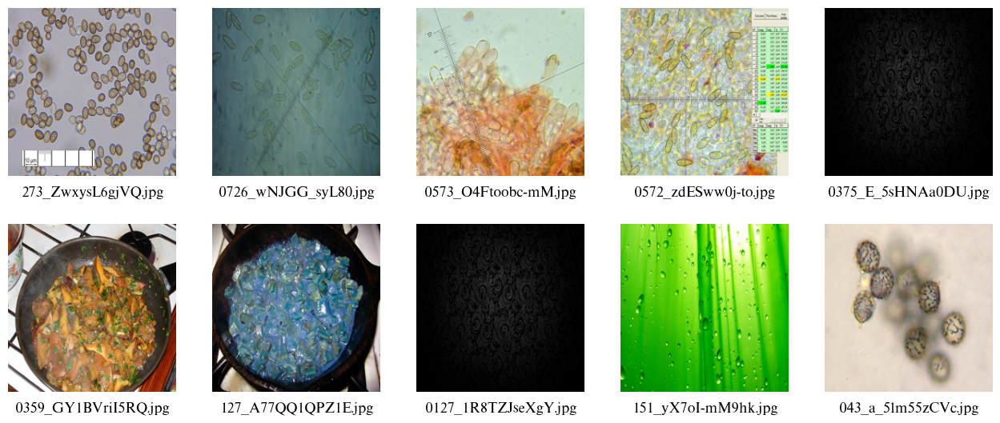

In [ ]:
visualization.vis_images(
    df=bad_img_vis_df,
    filepaths_col='filepaths',
    label_col='filename',
    n_rows=2,
    n_cols=5,
    title=None,
    fontsize=12
)

### **Intra duplicates**

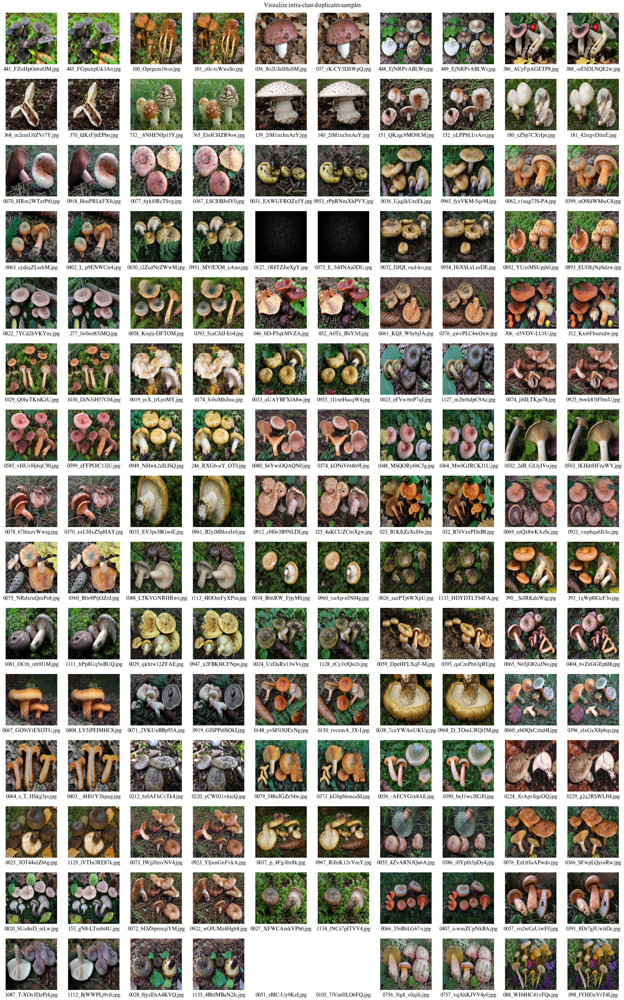

In [ ]:
visualization.vis_images(
    df=intra_report_df,
    filepaths_col='filepaths',
    label_col='filename',
    n_rows=15,
    n_cols=10,
    title='Visualize intra-class duplicates samples',
    fontsize=14
)

### **Inter duplicates**

In [ ]:
'''helperFunctions.vis_images(
    df=inter_report_df,
    filepaths_col='filepaths',
    label_col='filename',
    n_rows=1,
    n_cols=4,
    title='Visualize inter-class duplicates samples',
    fontsize=12
)'''

### **Dataset by class**

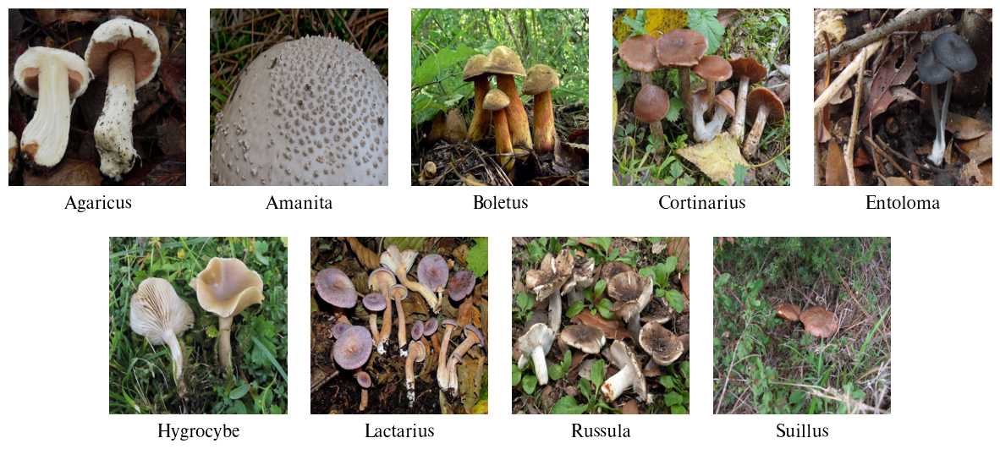

In [ ]:
unique_label = (
    metadata.groupby('labels', as_index=False).sample(n=1, random_state=SEED)
)

visualization.vis_images(
    df=unique_label,
    filepaths_col='filepaths',
    label_col='labels',
    n_rows=2,
    n_cols=5,
    target_size=(224, 224),
    figsize=(14, 6),
    fontsize=14,
    title=None,
    save_path=f'{drive_data_dir}/dataset_overview'
)

## **Section 5: Extra (Addition)**

### **Dataset Description**

In [ ]:
raw_metadata = pd.read_csv(f'{drive_data_dir}/raw_metadata.csv')
metadata = pd.read_csv(f'{drive_data_dir}/metadata.csv')
summary = pd.read_csv(f'{drive_data_dir}/summary.csv')

verify_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_VERIFY.csv')
outlier_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_OUTLIER.csv')
intra_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_INTRA_DUPLICATES.csv')
inter_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_INTER_DUPLICATES.csv')
to_delete_df = pd.read_csv(f'{bad_data_dir}/{data_name}_TO_DELETE.csv')

In [ ]:
raw_metadata = raw_metadata.sort_values(by='labels')
all_classes = raw_metadata['labels'].unique().tolist()

In [ ]:
summary_issue = pd.crosstab(
    to_delete_df['label'],
    to_delete_df['issue'],
    rownames=['Labels'],
    colnames=['IssueType']
)

all_possible_issues = ['candidateOutlier', 'corrupted', 'intraDuplicate', 'interDuplicate', 'solidColor']
summary_issue = summary_issue.reindex(index=all_classes, columns=all_possible_issues).fillna(0).astype(int)

summary_issue['Outlier'] = summary_issue['candidateOutlier']
summary_issue['Corrupted'] = summary_issue['corrupted'] + summary_issue['solidColor']
summary_issue['Duplicate'] = summary_issue['intraDuplicate'] + summary_issue['interDuplicate']

final_cols = ['Outlier', 'Corrupted', 'Duplicate']
summary_issue = summary_issue[final_cols].copy()
summary_issue['Count'] = summary_issue.sum(axis=1)

summary_issue = summary_issue.sort_index()

In [ ]:
summary = summary.rename(columns={'Total': 'Final Count'})

In [ ]:
raw_count_df = raw_metadata['labels'].value_counts().reset_index()
raw_count_df.columns = ['Labels', 'Initial Count']
raw_count_df = raw_count_df.sort_values(by='Labels').reset_index(drop=True)

In [ ]:
merged_1 = pd.merge(raw_count_df, summary, on='Labels')
column_order = ['Labels', 'Initial Count', 'Final Count', 'Remain (80 %)', 'Test (20 %)']
merged_1 = merged_1[column_order]

In [ ]:
merged_2 = pd.merge(merged_1, summary_issue, on='Labels')
re_order = ['Labels', 'Initial Count', 'Corrupted', 'Duplicate', 'Outlier', 'Count', 'Final Count', 'Remain (80 %)', 'Test (20 %)']
merged_2 = merged_2[re_order]
merged_2.to_csv(f'{drive_data_dir}/summary_desc.csv', index=False)
merged_2

,Labels,Initial Count,Corrupted,Duplicate,Outlier,Count,Final Count,Remain (80 %),Test (20 %)
0,Agaricus,353,0,2,1,3,350,280,70
1,Amanita,750,0,2,0,2,748,598,150
2,Boletus,1073,2,1,3,6,1067,854,213
3,Cortinarius,836,0,2,0,2,834,667,167
4,Entoloma,364,0,0,0,0,364,291,73
5,Hygrocybe,316,0,1,0,1,315,252,63
6,Lactarius,1563,0,61,4,65,1498,1198,300
7,Russula,1148,1,4,2,7,1141,913,228
8,Suillus,311,0,0,0,0,311,249,62


### **Augmentation Sample**

In [ ]:
with zipfile.ZipFile(f'{drive_data_dir}/{data_name}_SPLIT.zip', 'r') as zip_ref:
    zip_ref.extractall(runtime_datasplit_dir)
print(f'Dataset has been extracted to {runtime_datasplit_dir}')

Dataset has been extracted to /content/data/MushroomA_SPLIT


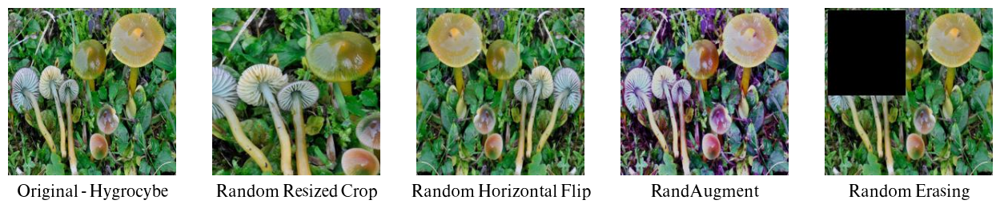

In [ ]:
from PIL import Image
import torchvision.transforms.v2 as v2
import torch

temp_dir = f"{runtime_dir}/temp_aug_vis"
os.makedirs(temp_dir, exist_ok=True)

img_size = (224, 224)
interp_mode = v2.InterpolationMode.BILINEAR

train_resize = v2.Compose([v2.Resize(img_size, interpolation=interp_mode)])
trans_crop = v2.Compose([v2.RandomResizedCrop(img_size, scale=(0.08, 1.0), interpolation=interp_mode)])
trans_flip = v2.Compose([train_resize, v2.RandomHorizontalFlip(p=1.0)])
trans_randaug = v2.Compose([train_resize, v2.RandAugment(num_ops=2, magnitude=6, interpolation=interp_mode)])
trans_erase = v2.Compose([
    train_resize,
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.RandomErasing(p=1.0, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0, inplace=False),
    v2.ToPILImage()
])

sample_image_data = [('/content/data/MushroomA_SPLIT/remain/Hygrocybe/004_uURYojZQbjQ.jpg', 'Hygrocybe')]
data = []

for i, (img_path, class_name) in enumerate(sample_image_data):
    img = Image.open(img_path).convert('RGB')

    # --- 1: Original  ---
    img_orig = img.resize(img_size)
    path_orig = f"{temp_dir}/img{i}_0_orig.jpg"
    img_orig.save(path_orig)
    data.append({'filepath': path_orig, 'label': f'Original - {class_name}'})

    # --- 2: Crop ---
    img_crop = trans_crop(img)
    path_crop = f"{temp_dir}/img{i}_1_crop.jpg"
    img_crop.save(path_crop)
    data.append({'filepath': path_crop, 'label': 'Random Resized Crop'})

    # --- 3: Flip ---
    img_flip = trans_flip(img)
    path_flip = f"{temp_dir}/img{i}_2_flip.jpg"
    img_flip.save(path_flip)
    data.append({'filepath': path_flip, 'label': 'Random Horizontal Flip'})

    # --- 4: RandAugment ---
    img_randaug = trans_randaug(img)
    path_randaug = f"{temp_dir}/img{i}_3_randaug.jpg"
    img_randaug.save(path_randaug)
    data.append({'filepath': path_randaug, 'label': 'RandAugment'})

    # --- 5: Erasing ---
    img_erase = trans_erase(img)
    path_erase = f"{temp_dir}/img{i}_4_erase.jpg"
    img_erase.save(path_erase)
    data.append({'filepath': path_erase, 'label': 'Random Erasing'})

df_vis = pd.DataFrame(data)

visualization.vis_images(
    df=df_vis,
    filepaths_col='filepath',
    label_col='label',
    n_rows=len(sample_image_data),
    n_cols=5,
    target_size=img_size,
    title=None,
    save_path=f'{drive_data_dir}/augmentation_sample'
)

In [ ]:
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from imagededup.methods import CNN

plt.rcParams['axes.unicode_minus'] = False
matlab_blue = '#0072BD'
matlab_orange = '#D95319'

pca_vis_dir = f"{drive_data_dir}/pcaVisualization"
os.makedirs(pca_vis_dir, exist_ok=True)

def apply_matlab_style(ax):
    ax.set_axisbelow(True)
    ax.grid(axis='both', color='#E5E5E5', linestyle='-', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#CCCCCC')
    ax.spines['bottom'].set_color('#CCCCCC')
    ax.tick_params(axis='both', colors='#333333', width=0.8, length=4)

def find_and_visualize_outliers(data_dir, target_class=None, seed=42, contamination=0.05, extensions=('.jpg', '.jpeg', '.png'), fontsize=16, save_path=None):
    cnn = CNN() # MobileNetV3 Default From imagededup library
    target_folders = []

    for root, dirs, files in os.walk(data_dir):
        has_images = any(f.lower().endswith(extensions) for f in files)
        if has_images:
            label_name = os.path.basename(root)
            if target_class is None or label_name == target_class:
                target_folders.append(root)

    print(f'Found {len(target_folders)} folders to process.')

    for folder_path in target_folders:
        label_name = os.path.basename(folder_path)
        print(f'\n--- Processing Class: {label_name} ---')

        try:
            encodings = cnn.encode_images(image_dir=folder_path)
            filenames = list(encodings.keys())
            vectors = np.array(list(encodings.values()))
            vectors_norm = normalize(vectors, norm='l2')

            clf = IsolationForest(
                contamination=contamination,
                n_estimators=200,
                random_state=seed,
                n_jobs=-1
            )
            clf.fit(vectors_norm)
            preds = clf.predict(vectors_norm)

            outlier_count = list(preds).count(-1)
            print(f'Class {label_name}: Found {outlier_count} candidate outliers.')

            pca = PCA(n_components=2, random_state=seed)
            vectors_2d = pca.fit_transform(vectors_norm)

            preds_arr = np.array(preds)
            normal_idx = preds_arr == 1
            outlier_idx = preds_arr == -1

            fig, ax = plt.subplots(figsize=(10, 6))
            ax.scatter(vectors_2d[normal_idx, 0], vectors_2d[normal_idx, 1],
                       c=matlab_blue, label='Normal (Inliers)', alpha=0.6, s=50, edgecolors='w')
            ax.scatter(vectors_2d[outlier_idx, 0], vectors_2d[outlier_idx, 1],
                       c=matlab_orange, label='Candidate Outliers', alpha=0.9, s=80, marker='X', edgecolors='k')

            var_ratio = pca.explained_variance_ratio_
            print(var_ratio)

            ax.set_title(f'Isolation Forest: Normal vs Candidate Outliers (Class {label_name})', fontsize=fontsize)
            ax.set_xlabel(f'Principal Component 1 ({var_ratio[0]:.2%} Variance)', fontsize=fontsize)
            ax.set_ylabel(f'Principal Component 2 ({var_ratio[1]:.2%} Variance)', fontsize=fontsize)

            ax.tick_params(axis='both', labelsize=fontsize - 2)

            ax.legend(fontsize=fontsize)
            apply_matlab_style(ax)

            plt.tight_layout()
            if save_path:
                plt.savefig(f'{save_path}/pca_vis_{label_name}.png', dpi=300, bbox_inches='tight')
                plt.savefig(f'{save_path}/pca_vis_{label_name}.svg', bbox_inches='tight')
            plt.show()

        except Exception as e:
            print(f'Error processing folder {folder_path}: {e}')

2026-04-01 09:17:16,991: INFO Device set to cpu ..
INFO:imagededup.methods.cnn:Device set to cpu ..
2026-04-01 09:17:16,996: INFO Initialized: mobilenet_v3_small for feature extraction ..
INFO:imagededup.methods.cnn:Initialized: mobilenet_v3_small for feature extraction ..
2026-04-01 09:17:17,010: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation


Found 9 folders to process.

--- Processing Class: Entoloma ---


2026-04-01 09:17:22,535: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Entoloma: Found 19 candidate outliers.
[0.13124235 0.07914648]


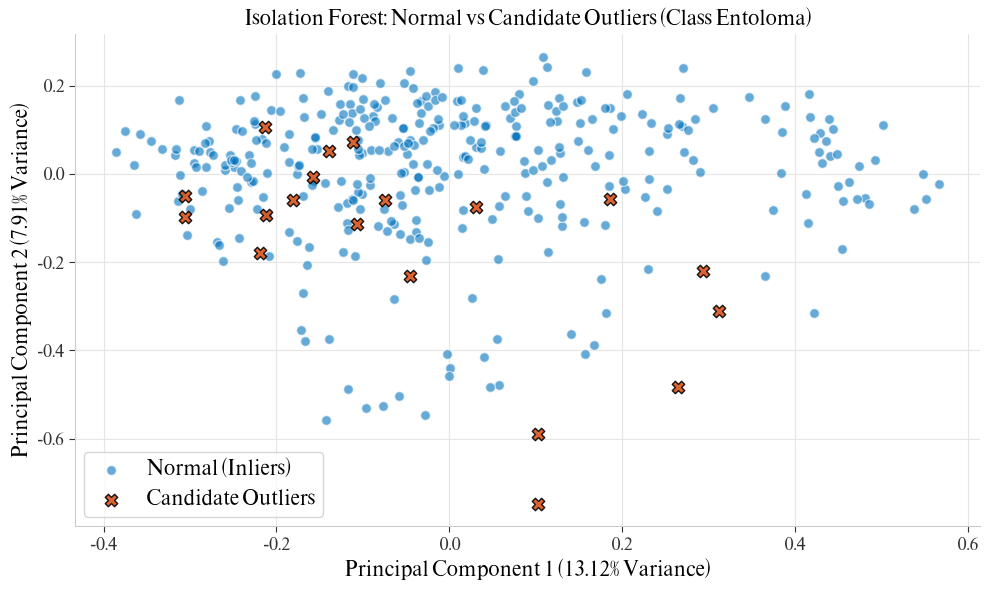

2026-04-01 09:17:23,635: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation



--- Processing Class: Boletus ---


2026-04-01 09:17:40,079: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Boletus: Found 54 candidate outliers.
[0.08977684 0.06163687]


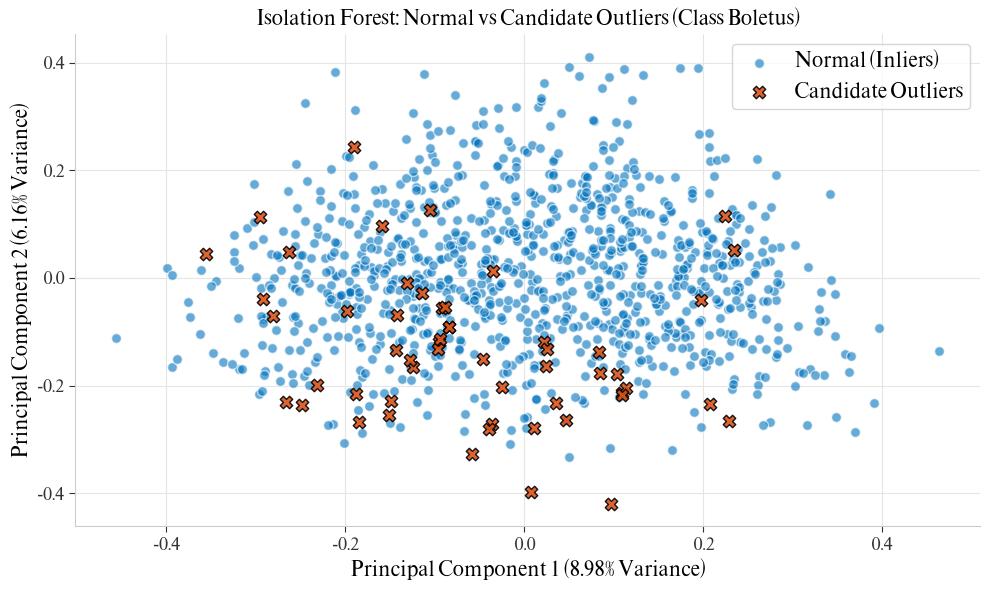

2026-04-01 09:17:41,821: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation



--- Processing Class: Agaricus ---


2026-04-01 09:17:47,274: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Agaricus: Found 18 candidate outliers.
[0.09784759 0.07870753]


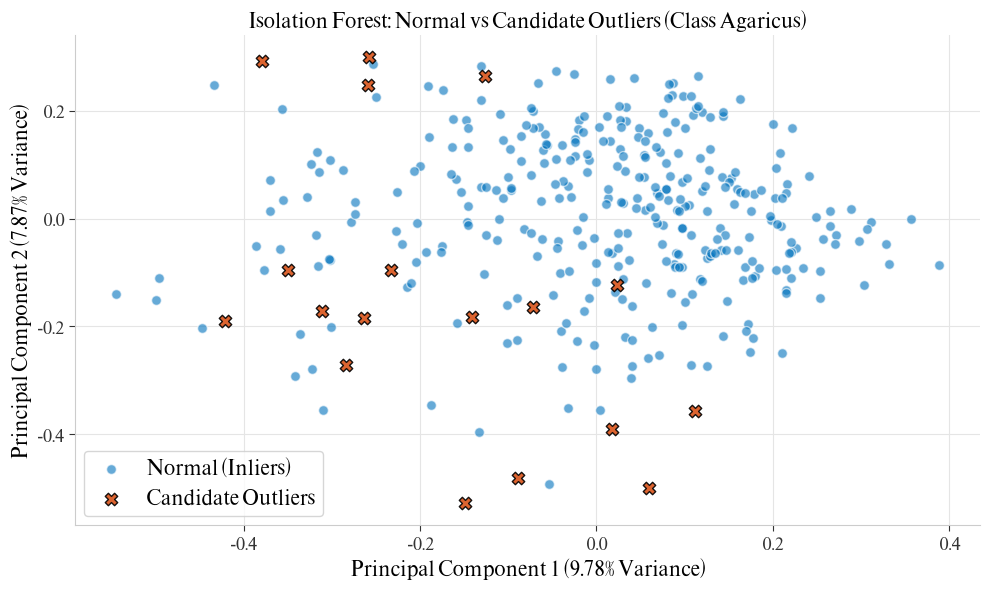

2026-04-01 09:17:48,390: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation



--- Processing Class: Suillus ---


2026-04-01 09:17:53,245: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Suillus: Found 16 candidate outliers.
[0.10588284 0.06283692]


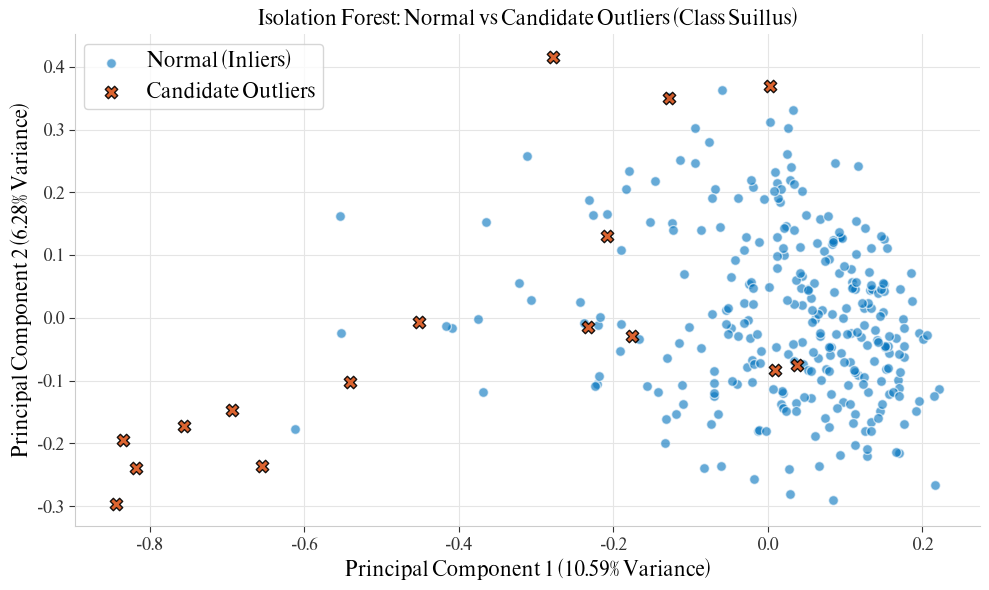

2026-04-01 09:17:54,853: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation



--- Processing Class: Amanita ---


2026-04-01 09:18:06,663: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Amanita: Found 38 candidate outliers.
[0.09037929 0.06968708]


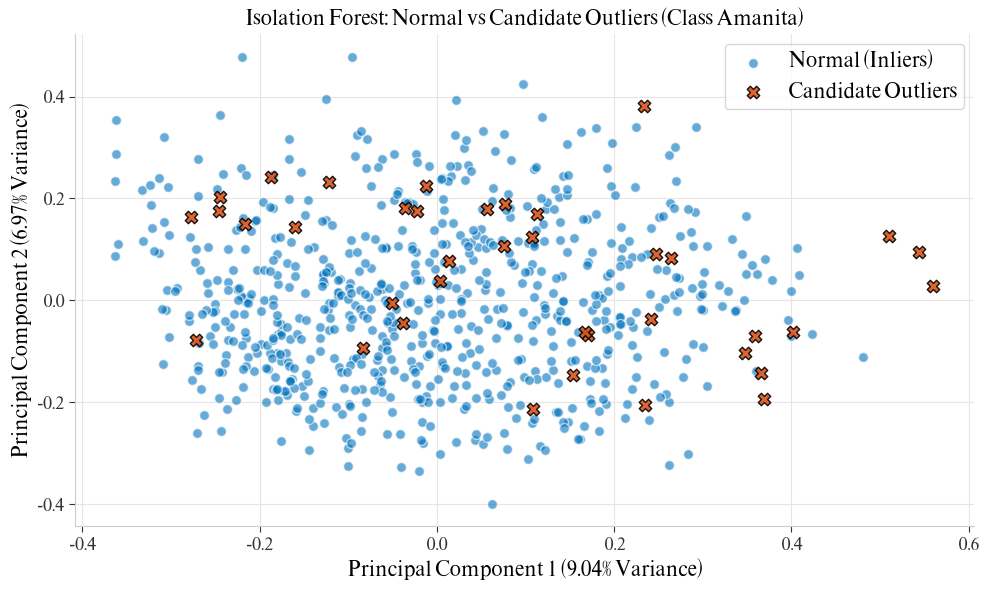

2026-04-01 09:18:07,987: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation



--- Processing Class: Russula ---


2026-04-01 09:18:25,285: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Russula: Found 58 candidate outliers.
[0.13063617 0.07379337]


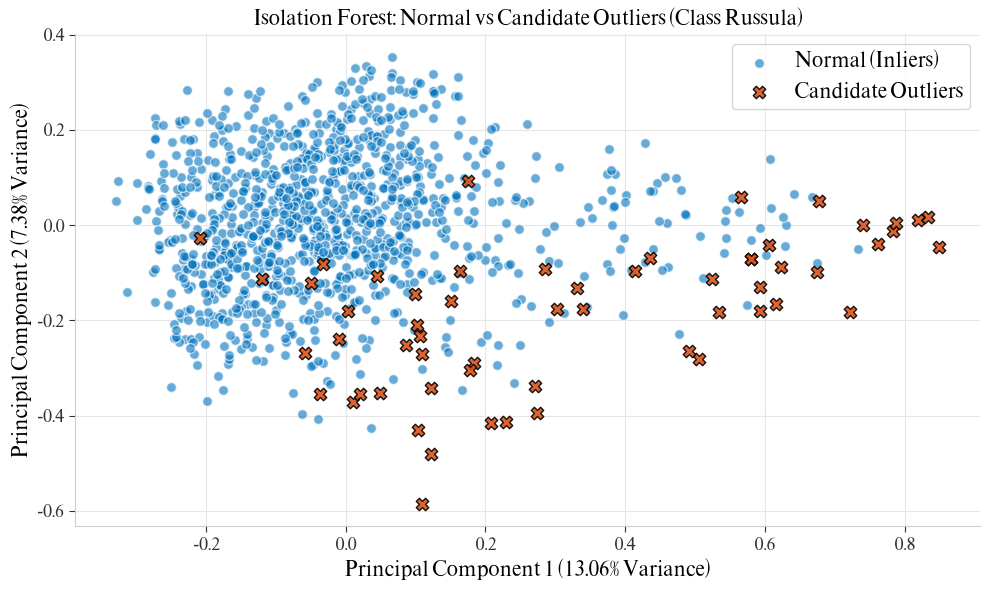

2026-04-01 09:18:26,640: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation



--- Processing Class: Hygrocybe ---


2026-04-01 09:18:31,844: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Hygrocybe: Found 16 candidate outliers.
[0.12664764 0.0685968 ]


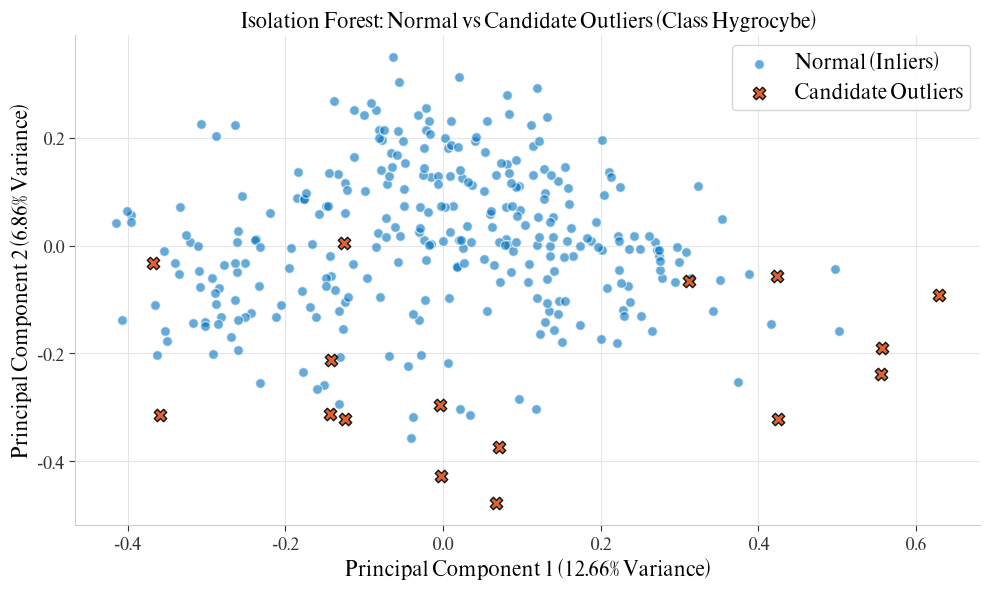

2026-04-01 09:18:32,997: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation



--- Processing Class: Cortinarius ---


2026-04-01 09:18:46,424: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Cortinarius: Found 42 candidate outliers.
[0.11073591 0.07174664]


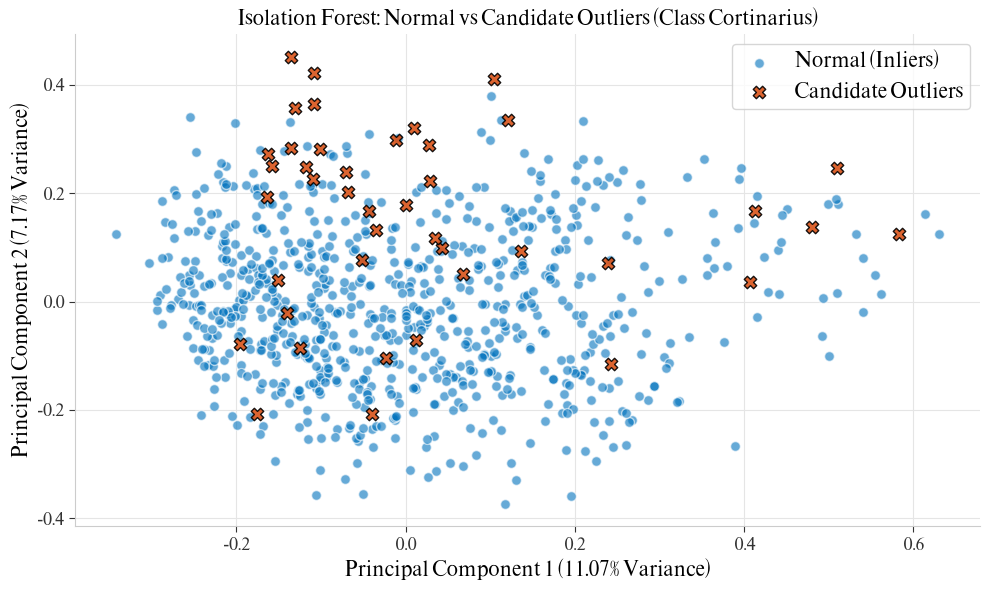

2026-04-01 09:18:47,649: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation



--- Processing Class: Lactarius ---


2026-04-01 09:19:12,765: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Lactarius: Found 79 candidate outliers.
[0.10560441 0.07840166]


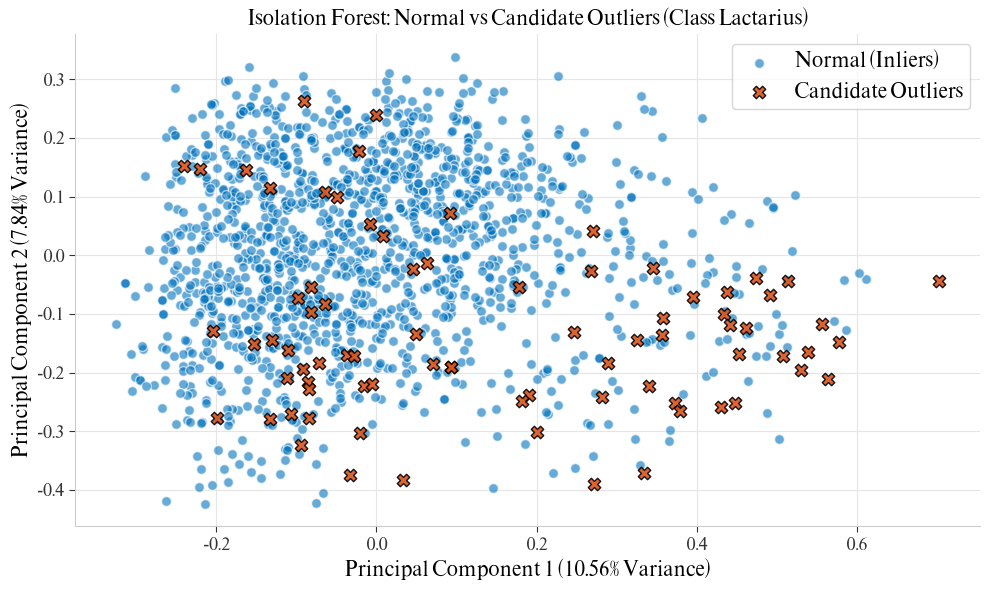

In [ ]:
find_and_visualize_outliers(data_dir=runtime_data_dir, target_class=None, seed=SEED, contamination=0.05, extensions=('.jpg', '.jpeg', '.png'), fontsize=14, save_path=pca_vis_dir)